In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from itables import init_notebook_mode
init_notebook_mode(all_interactive=True)

In [2]:
RECALL_ROOT = Path("/home/morg/NLP_2526b/shaharmayo/NLPFinalProject/data/artifacts/recall")

# NOTE this set varies TWO things, unlike the 600M notebook's corpus ladder:
# explicit_1E vs original_1E is the clean corpus contrast at matched epochs, while
# explicit_2E adds a second epoch on top of the same rewritten corpus.  So
# explicit_2E vs explicit_1E is an epochs effect, not a corpus effect, and
# explicit_2E vs original_1E confounds the two.  Read the pairwise table below
# with that in mind.
RUNS = {
    "original_1E": dict(
        path=RECALL_ROOT / "original_corpus/locally_trained_models/original_170M_1E"
                         / "recall_step109672_15shot_recallonly.parquet",
        replaced=0, tokens=3_795_178_761, epochs=1,
    ),
    "explicit_1E": dict(
        path=RECALL_ROOT / "translated_corpus/explicit_170M_1E"
                         / "recall_step113720_15shot_recallonly.parquet",
        replaced=53_114_734, tokens=3_932_099_672, epochs=1,
    ),
    "explicit_2E": dict(
        path=RECALL_ROOT / "translated_corpus/explicit_170M_2E"
                         / "recall_step227440_15shot_recallonly.parquet",
        replaced=53_114_734, tokens=2 * 3_932_099_672, epochs=2,
    ),
}
ARMS = list(RUNS)
BASELINE_ARM = ARMS[0]        # the arm every delta is measured against

DROP_EXCLUDED = False
DROP_ZERO_CHUNKS = True
# Questions held back from evaluation because they serve as the few-shot
# demonstrations, listed in data/artifacts/popqa/fewshot_withheld_15shot.csv (19 ids,
# derived as: all PopQA ids minus the ids present in a *_15shot_recallonly
# parquet; identical across every one of them).  The 15-shot result files already
# omit these, so this flag is a no-op on the recall side -- it matters for
# statistics computed from the FULL PopQA table, which otherwise describe a
# benchmark 19 questions larger than the one the models were scored on.
DROP_FEWSHOT_DEMOS = True
FEWSHOT_WITHHELD_CSV = Path("/home/morg/NLP_2526b/shaharmayo/NLPFinalProject/data/artifacts/popqa/fewshot_withheld_15shot.csv")

KEEP_COLS = ["id", "correct", "generation"]
CHUNK_EDGES = [0, 1, 10, 100, 1_000, float("inf")]
CHUNK_LABELS = ["0", "1-10", "10-100", "100-1k", "1k+"]
ARM_COLOR = {"original_1E": "#2a78d6", "explicit_1E": "#eb6834",
             "explicit_2E": "#1baf7a"}

In [3]:

# PopQA metadata: relation type and corpus co-occurrence count per question.
# Loaded BEFORE the recall parquets because DROP_ZERO_CHUNKS is defined by
# num_shared_chunks, and the filter has to be applied once, up front, or the
# headline number and the per-bin numbers end up computed over different rows.
from datasets import load_dataset

ds = load_dataset("dhgottesman/popqa-kas")
qa = ds["train"].to_pandas()[["id", "prop", "num_shared_chunks", "question"]]

# Facts whose subject and object never share a corpus chunk: the model had no
# co-occurrence to learn from, so recall on them is near the floor for every arm.
_wh = pd.read_csv(FEWSHOT_WITHHELD_CSV)
WITHHELD_IDS = frozenset(_wh["id"]) if DROP_FEWSHOT_DEMOS else frozenset()
print(f"few-shot withheld: {len(_wh)} ids in {FEWSHOT_WITHHELD_CSV.name}"
      f"  (applied: {DROP_FEWSHOT_DEMOS})")

ZERO_IDS = frozenset(qa.loc[qa["num_shared_chunks"] == 0, "id"])
print(f"{len(qa):,} PopQA rows | {qa['prop'].nunique()} relations "
      f"| {len(ZERO_IDS):,} with num_shared_chunks == 0")
qa.head()


few-shot withheld: 19 ids in fewshot_withheld_15shot.csv  (applied: True)
14,267 PopQA rows | 16 relations | 2,450 with num_shared_chunks == 0


Loading ITables v2.8.1 from the init_notebook_mode cell... (need help?)


In [4]:

rows = []
for arm, r in RUNS.items():
    if not r["path"].exists():
        print(f"MISSING {arm}: {r['path']}")
        continue
    step = int(r["path"].name.split("recall_step")[1].split("_")[0])
    rows.append({"arm": arm, "step": step, "epochs": r["epochs"],
                 "replaced": r["replaced"], "tokens": r["tokens"], "path": r["path"]})
runs = pd.DataFrame(rows)

# The arms are only comparable if they were scored on the SAME prompts.
_frames = {r.arm: pd.read_parquet(r.path).sort_values("id") for r in runs.itertuples()}
_base_arm, _base = next(iter(_frames.items()))
for _arm, _f in _frames.items():
    if _arm == _base_arm:
        continue
    ok = ((_base["id"].values == _f["id"].values).all()
          and (_base["prompt"].values == _f["prompt"].values).all())
    print(f"{'ok' if ok else 'MISMATCH'}: {_arm} scored on the same prompts as {_base_arm}")


def load_run(row) -> pd.DataFrame:
    """Recall for one arm, with both row filters applied.

    Every frame in this notebook is built from this function, so DROP_EXCLUDED and
    DROP_ZERO_CHUNKS cannot end up applied to some tables and not others.
      DROP_EXCLUDED     - facts whose answer already appears in the query; olmes
                          drops them, and they are ~53% correct against a ~5% base
                          rate, so keeping them inflates every arm equally.
      DROP_ZERO_CHUNKS  - facts that never co-occur in the corpus (num_shared_chunks
                          == 0).  Restricts the benchmark to facts the corpus could
                          actually have taught.
    """
    df = pd.read_parquet(row.path)
    if DROP_EXCLUDED and "excluded" in df.columns:
        df = df[~df["excluded"].astype(bool)]
    if DROP_ZERO_CHUNKS:
        df = df[~df["id"].isin(ZERO_IDS)]
    if DROP_FEWSHOT_DEMOS:
        df = df[~df["id"].isin(WITHHELD_IDS)]
    df = df[[c for c in KEEP_COLS if c in df.columns]].copy()
    df["arm"] = row.arm
    return df


long_df = pd.concat([load_run(r) for r in runs.itertuples()], ignore_index=True)
long_df["arm"] = pd.Categorical(long_df["arm"], categories=ARMS, ordered=True)

# With the zero bin filtered out there is nothing to plot in it; drop the label so
# plot 1 does not render an empty panel.
ACTIVE_CHUNK_LABELS = [b for b in CHUNK_LABELS if not (DROP_ZERO_CHUNKS and b == "0")]

_per_arm = len(long_df) // len(ARMS)
print(f"DROP_EXCLUDED={DROP_EXCLUDED}  DROP_ZERO_CHUNKS={DROP_ZERO_CHUNKS}"
      f"  ->  {_per_arm:,} questions per arm  (of 14,248 scored)")
long_df.head()


ok: explicit_1E scored on the same prompts as original_1E
ok: explicit_2E scored on the same prompts as original_1E
DROP_EXCLUDED=False  DROP_ZERO_CHUNKS=True  ->  11,799 questions per arm  (of 14,248 scored)


Loading ITables v2.8.1 from the init_notebook_mode cell... (need help?)


In [5]:
wide_df = None
for row in runs.itertuples():
    part = load_run(row).drop(columns=["arm"])
    part = part.rename(columns={c: f"{row.arm}_{c}" for c in part.columns if c != "id"})
    wide_df = part if wide_df is None else wide_df.merge(part, on="id", how="outer")

correct_cols = [f"{a}_correct" for a in ARMS if f"{a}_correct" in wide_df.columns]
generation_cols = [f"{a}_generation" for a in ARMS if f"{a}_generation" in wide_df.columns]
wide_df = wide_df[["id", *correct_cols, *generation_cols]]

print(wide_df.shape)
wide_df[["id", *correct_cols]].head()

(11799, 7)


Loading ITables v2.8.1 from the init_notebook_mode cell... (need help?)


In [6]:

import numpy as np

scored = long_df.merge(qa[["id", "prop", "num_shared_chunks"]], on="id", how="inner")
scored["chunk_bin"] = pd.cut(scored["num_shared_chunks"], bins=CHUNK_EDGES,
                             labels=CHUNK_LABELS, right=False)
assert len(scored) == len(long_df), "qa merge dropped rows -- ids do not line up"


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """95% CI for a proportion.  The 1k+ bin is only ~290 questions, so a bare
    point estimate there invites over-reading."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))


def recall_by(group_cols) -> pd.DataFrame:
    """Recall + Wilson CI, grouped.  Pass [] for the overall figure -- deriving it
    from `scored` too keeps the headline over exactly the rows the bins cover."""
    keys = [*group_cols, "arm"]
    g = (scored.groupby(keys, as_index=False, observed=True)
                .agg(n=("correct", "size"), n_correct=("correct", "sum")))
    g["recall"] = g["n_correct"] / g["n"]
    ci = g.apply(lambda r: wilson(r.n_correct, r.n), axis=1)
    g["lo"], g["hi"] = [c[0] for c in ci], [c[1] for c in ci]
    return g


overall = recall_by([])
by_bin = recall_by(["chunk_bin"])

bin_matrix = by_bin.pivot(index="chunk_bin", columns="arm", values="recall")[ARMS]
bin_matrix["n"] = by_bin[by_bin["arm"] == BASELINE_ARM].set_index("chunk_bin")["n"]
bin_matrix = bin_matrix.loc[ACTIVE_CHUNK_LABELS]
(bin_matrix.assign(**{a: (bin_matrix[a] * 100).round(2) for a in ARMS}))


Loading ITables v2.8.1 from the init_notebook_mode cell... (need help?)


In [7]:

# Headline recall per arm, and the paired test.  The arms are scored on identical
# prompts, so McNemar on the per-question disagreements is the right test -- far
# more powerful than comparing two independent proportions.
from itertools import combinations
from math import erfc, sqrt

both = overall.set_index("arm").loc[ARMS, ["n", "n_correct", "recall"]].copy()
both[f"delta_vs_{BASELINE_ARM}"] = both["recall"] - both.loc[BASELINE_ARM, "recall"]


def mcnemar(a: str, b: str) -> dict:
    """b vs a, over the filtered rows only.  n01 = only b correct."""
    x = long_df[long_df["arm"] == a].set_index("id")["correct"].astype(int).sort_index()
    y = long_df[long_df["arm"] == b].set_index("id")["correct"].astype(int).sort_index()
    n01 = int(((x == 0) & (y == 1)).sum())
    n10 = int(((x == 1) & (y == 0)).sum())
    chi2 = (abs(n10 - n01) - 1) ** 2 / (n10 + n01) if (n10 + n01) else 0.0
    return {"comparison": f"{b} vs {a}", "diff_pp": 100 * (y.mean() - x.mean()),
            "only_later": n01, "only_earlier": n10,
            "chi2": chi2, "p": erfc(sqrt(chi2 / 2))}


pairs = pd.DataFrame([mcnemar(a, b) for a, b in combinations(ARMS, 2)])
display(both.assign(**{"recall": (both["recall"] * 100).round(3),
                   f"delta_vs_{BASELINE_ARM}":
                       (both[f"delta_vs_{BASELINE_ARM}"] * 100).round(3)}))
pairs.round({"diff_pp": 3, "chi2": 2})


Loading ITables v2.8.1 from the init_notebook_mode cell... (need help?)


Loading ITables v2.8.1 from the init_notebook_mode cell... (need help?)


/tmp/ipykernel_1684131/1908691462.py:85: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 1 - 0.20 / bin_rows))


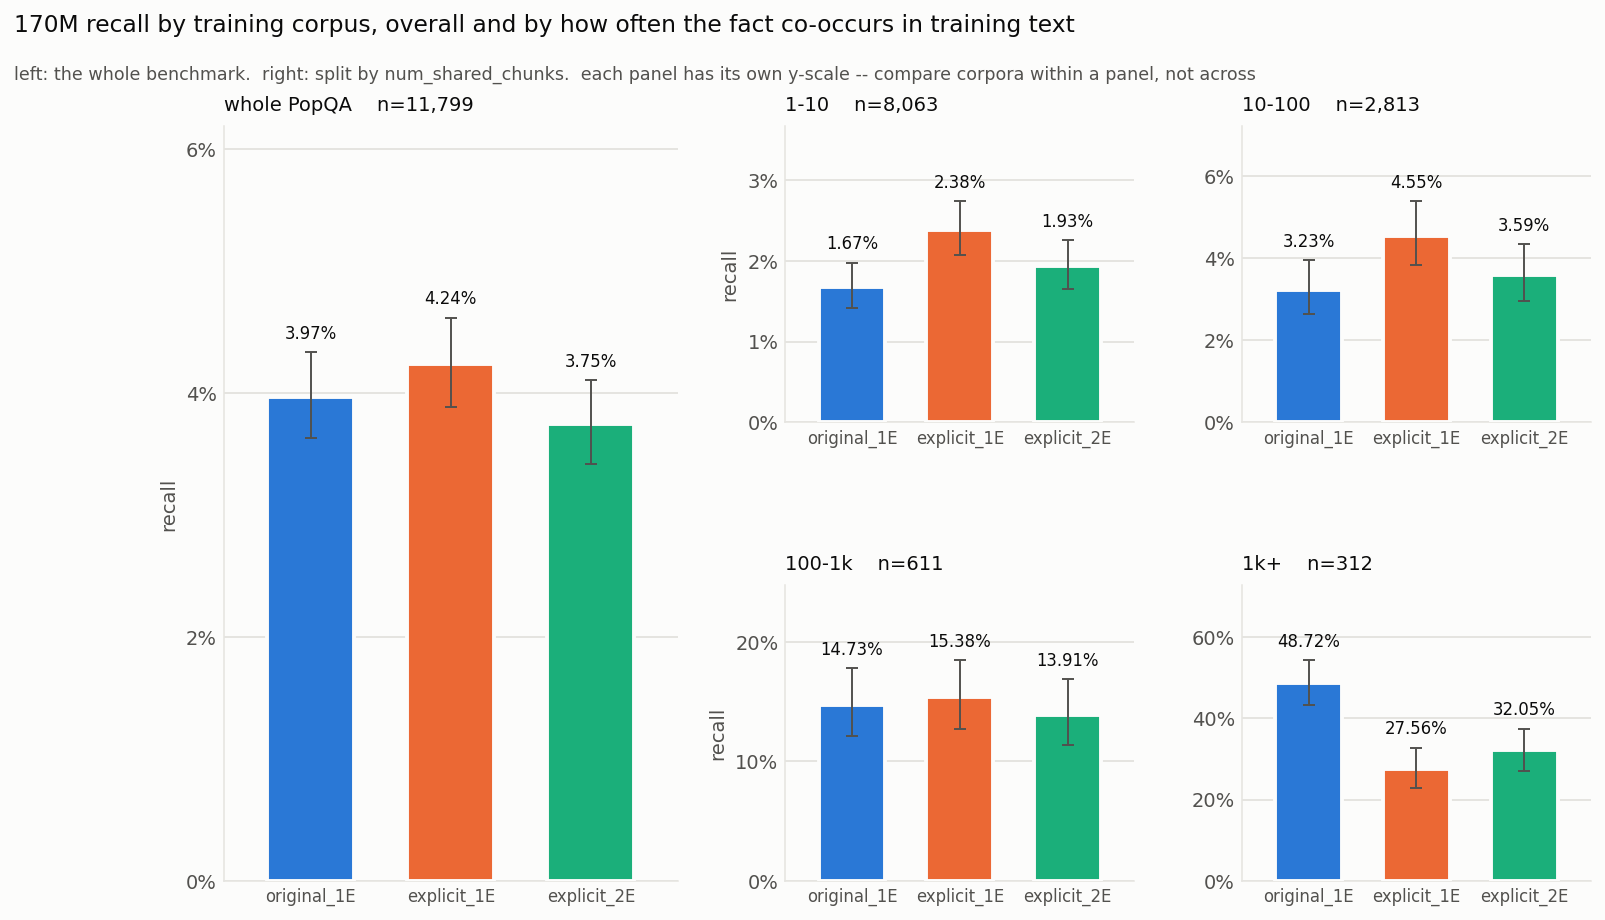

In [8]:

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_MUTED = "#52514e"
GRID = "#e5e4e0"

# Small multiples, one panel per group, EACH WITH ITS OWN LINEAR y-AXIS.
# Recall spans roughly two orders of magnitude across the bins, so a single
# shared axis cannot work: linear buries the low bins, and a log axis hides the
# differences because bar length stops being proportional to value on a log scale.  Faceting fixes both -- every panel is
# linear from zero, so bar length is honest again, and each panel's range is
# scaled to its own data so the between-corpus differences stay visible.
#
# Layout: the whole-PopQA summary gets its own full-height panel on the left, and
# the co-occurrence bins sit in a grid to its right (2 x 2 with the zero bin
# dropped, 2 x 3 with it kept).  Reading order is summary first, then bins.
#
# The trade-off is that heights are NOT comparable ACROSS panels; the per-panel
# axis and the printed percentages are there to keep that clear.
BIN_COLS = 2
bin_rows = -(-len(ACTIVE_CHUNK_LABELS) // BIN_COLS)

fig = plt.figure(figsize=(12.6, 3.5 * bin_rows), dpi=140)
fig.patch.set_facecolor(SURFACE)
gs = fig.add_gridspec(bin_rows, 1 + BIN_COLS,
                      width_ratios=[1.3] + [1.0] * BIN_COLS,
                      hspace=0.55, wspace=0.28)

ax_all = fig.add_subplot(gs[:, 0])                      # spans every row
bin_axes = [fig.add_subplot(gs[j // BIN_COLS, 1 + j % BIN_COLS])
            for j in range(len(ACTIVE_CHUNK_LABELS))]

xs = np.arange(len(ARMS))


def draw_panel(ax, label, sub, n, *, show_ylabel):
    ax.set_facecolor(SURFACE)
    tops = np.array([sub.loc[a, "recall"] for a in ARMS])
    los = np.array([sub.loc[a, "lo"] for a in ARMS])
    his = np.array([sub.loc[a, "hi"] for a in ARMS])

    ax.bar(xs, tops, width=0.62, color=[ARM_COLOR[a] for a in ARMS],
           edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.errorbar(xs, tops, yerr=[tops - los, his - tops], fmt="none",
                ecolor=INK_MUTED, elinewidth=1, capsize=3, zorder=4)
    for x, top, hi in zip(xs, tops, his):
        ax.annotate(f"{top:.2%}", xy=(x, hi), xytext=(0, 5),
                    textcoords="offset points", ha="center", va="bottom",
                    fontsize=8.5, color=INK)

    ax.set_ylim(0, min(his.max() * 1.34, 1.0))
    # steps=[1,2,5,10] forces ticks onto whole percents.  Without it MaxNLocator
    # lands on values like 2.5% / 7.5% which the 0-decimal formatter then prints
    # as "2%" / "8%" -- a gridline labelled with a number it is not at.
    ax.yaxis.set_major_locator(plt.MaxNLocator(4, steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_xticks(xs)
    ax.set_xticklabels(ARMS, fontsize=8.5)
    ax.set_xlim(-0.62, len(ARMS) - 0.38)
    ax.set_title(f"{label}    n={n:,}", fontsize=10, color=INK, loc="left", pad=8)
    if show_ylabel:
        ax.set_ylabel("recall", fontsize=10, color=INK_MUTED)
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_MUTED, length=0)


draw_panel(ax_all, "whole PopQA", overall.set_index("arm"),
           int(overall["n"].iloc[0]), show_ylabel=True)
for j, (ax, b) in enumerate(zip(bin_axes, ACTIVE_CHUNK_LABELS)):
    sub = by_bin[by_bin["chunk_bin"] == b].set_index("arm")
    draw_panel(ax, b, sub, int(sub["n"].iloc[0]),
               show_ylabel=(j % BIN_COLS == 0))

fig.suptitle(
    "170M recall by training corpus, overall and by how often the fact co-occurs in training text",
    fontsize=12, color=INK, x=0.006, ha="left", y=0.995)
fig.text(0.006, 1 - 0.145 / bin_rows,
         "left: the whole benchmark.  right: split by num_shared_chunks.  "
         "each panel has its own y-scale -- compare corpora within a panel, not across",
         fontsize=9, color=INK_MUTED, ha="left")
fig.tight_layout(rect=(0, 0, 1, 1 - 0.20 / bin_rows))
plt.show()


In [9]:
by_prop = recall_by(["prop"])
prop_matrix = by_prop.pivot(index="prop", columns="arm", values="recall")[ARMS]
prop_matrix["n"] = by_prop[by_prop["arm"] == BASELINE_ARM].set_index("prop")["n"]
for arm in ARMS[1:]:
    prop_matrix[f"delta_{arm}"] = prop_matrix[arm] - prop_matrix[BASELINE_ARM]
prop_matrix = prop_matrix.sort_values(f"delta_{ARMS[-1]}", ascending=False)
(prop_matrix.assign(**{c: (prop_matrix[c] * 100).round(2)
                       for c in prop_matrix.columns if c != "n"}))

Loading ITables v2.8.1 from the init_notebook_mode cell... (need help?)


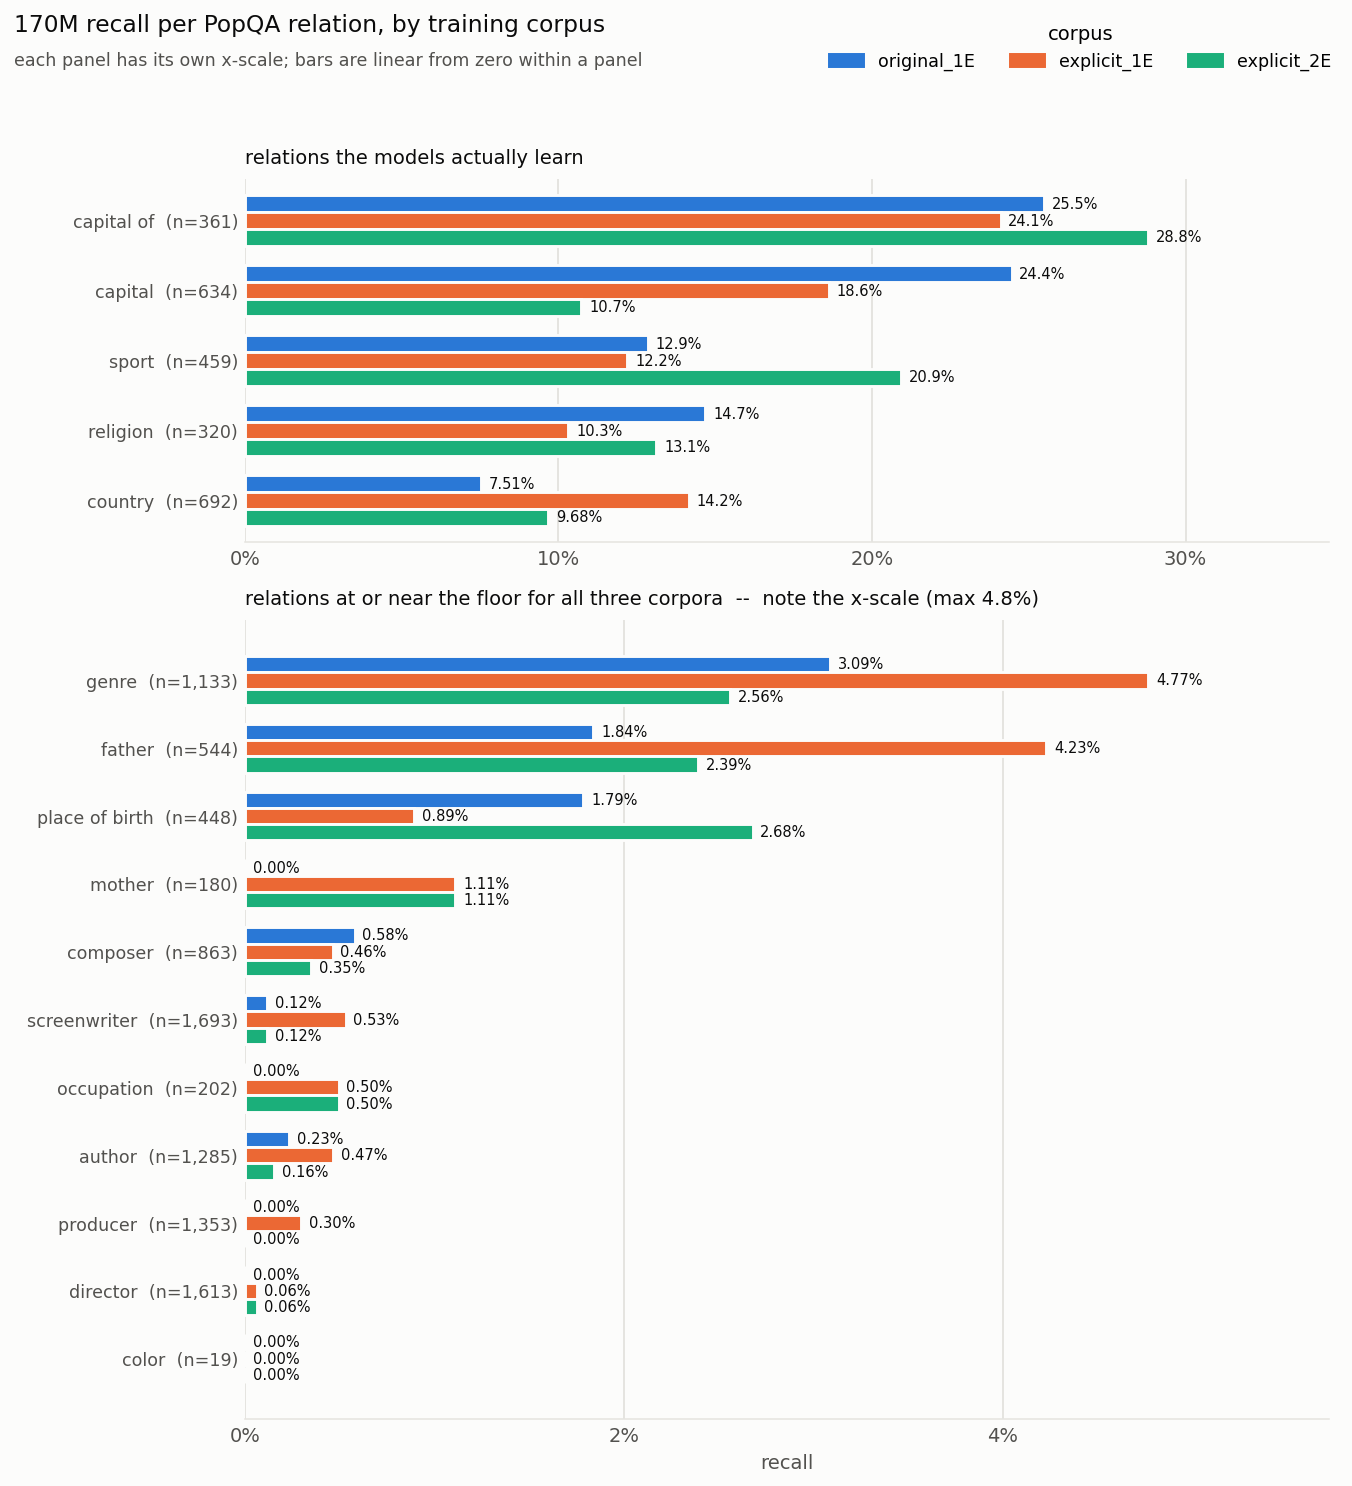

In [10]:

# Absolute recall per relation, one bar per corpus -- not the delta.  A delta
# hides the thing that matters most here: for over half the relations ALL THREE
# models sit at or near zero, so a "-0.1 pp" there is noise against an unlearned
# relation, not a regression.
# Showing levels makes that visible, and three bars side by side still show the
# difference.  (The signed deltas remain in prop_matrix above.)
#
# Split by magnitude for the same reason plot 1 is faceted: the spread across
# relations is wide enough that one shared x-axis would flatten most of them
# into a single line at zero.  Each panel is linear from zero; only the x-range differs.
LEARNED_MIN = 0.05                       # max recall across arms to count as learned
peak = prop_matrix[ARMS].max(axis=1)
learned = prop_matrix.loc[peak >= LEARNED_MIN].sort_values(
    by=list(ARMS), ascending=False, key=lambda s: s)
learned = prop_matrix.loc[peak >= LEARNED_MIN].assign(_p=peak).sort_values("_p", ascending=False)
floor = prop_matrix.loc[peak < LEARNED_MIN].assign(_p=peak).sort_values("_p", ascending=False)

h = 0.24
fig2, axes2 = plt.subplots(
    2, 1, figsize=(9.6, 10.6), dpi=140,
    gridspec_kw={"height_ratios": [len(learned), len(floor)]})
fig2.patch.set_facecolor(SURFACE)

panels = [
    (axes2[0], learned, "relations the models actually learn"),
    (axes2[1], floor,
     f"relations at or near the floor for all three corpora  --  note the x-scale "
     f"(max {floor[ARMS].max().max():.1%})"),
]

for ax, block, title in panels:
    ax.set_facecolor(SURFACE)
    y = np.arange(len(block))
    for i, arm in enumerate(ARMS):
        vals = block[arm].values
        ax.barh(y + (i - 1) * h, vals, height=h, color=ARM_COLOR[arm],
                edgecolor=SURFACE, linewidth=1.5,
                label=arm if ax is axes2[0] else None, zorder=3)
        # All labels outside the bar end, in dark ink.  Note this can crowd where a
        # short bar sits next to a much longer one in the same relation; the 1.20
        # xlim headroom below is what keeps the longest ones from clipping.
        for yi, v in zip(y + (i - 1) * h, vals):
            txt = f"{v:.1%}" if v >= 0.10 else f"{v:.2%}"
            ax.annotate(txt, xy=(v, yi), xytext=(4, 0), textcoords="offset points",
                        va="center", ha="left", fontsize=7.5, color=INK, zorder=5)

    ax.set_yticks(y)
    ax.set_yticklabels(
        [f"{p}  (n={int(block.loc[p, 'n']):,})" for p in block.index], fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, block[ARMS].max().max() * 1.20)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5, steps=[1, 2, 5, 10]))
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}" if v >= 0.01 or v == 0 else f"{v:.1%}")
    ax.set_title(title, fontsize=10, color=INK, loc="left", pad=8)
    ax.grid(axis="x", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_MUTED, length=0)

axes2[1].set_xlabel("recall", fontsize=10, color=INK_MUTED)
# Figure-level legend in the header, so neither panel's bars can push it around.
handles = [plt.Rectangle((0, 0), 1, 1, color=ARM_COLOR[a]) for a in ARMS]
fig2.legend(handles, list(ARMS), title="corpus", frameon=False, ncols=3,
            loc="upper right", bbox_to_anchor=(0.998, 1.0), fontsize=9)

fig2.suptitle("170M recall per PopQA relation, by training corpus",
              fontsize=12, color=INK, x=0.006, ha="left", y=0.997)
fig2.text(0.006, 0.962,
          "each panel has its own x-scale; bars are linear from zero within a panel",
          fontsize=9, color=INK_MUTED, ha="left")
fig2.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()


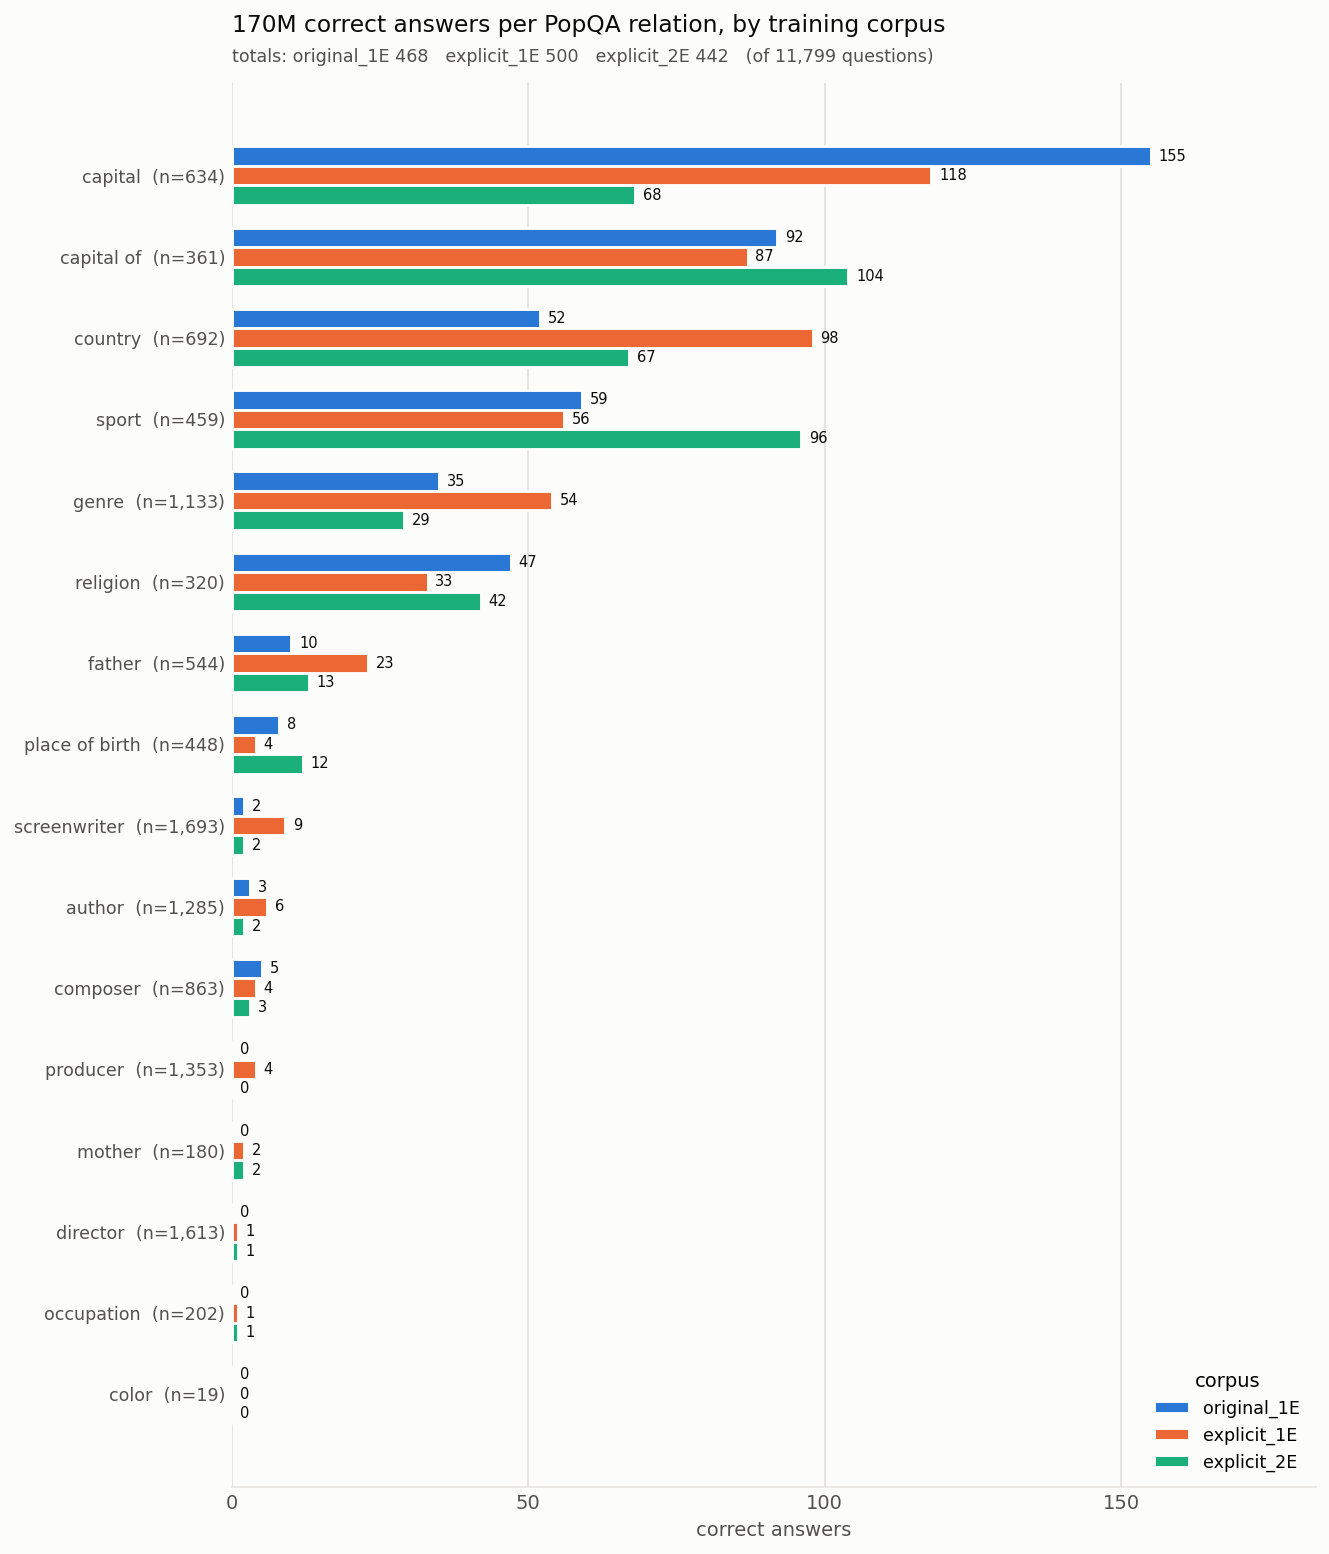

In [11]:

# Same chart as above, but COUNT of correct answers instead of recall rate.
# The two are not redundant: rate divides by the number of questions in a relation,
# count does not, so they rank relations differently.  genre is 3.6% recall but 41
# correct on a large denominator; color has few questions so a decent rate is
# only a couple of answers.  Rate answers "how
# reliable is the model on this relation", count answers "where do the extra correct
# answers actually come from".
#
# One shared x-axis, unlike the rate chart above.  Rates needed splitting because a
# relation at 0.1% and one at 47% carry equally real information and the small one
# would vanish.  Counts do not: a relation with 2 correct answers contributes almost
# nothing to the total, so letting the largest relation dominate the axis IS the
# message.
# The printed numbers keep the tail readable.
count_matrix = by_prop.pivot(index="prop", columns="arm", values="n_correct")[ARMS]
count_matrix["n"] = by_prop[by_prop["arm"] == BASELINE_ARM].set_index("prop")["n"]
count_matrix = count_matrix.assign(_p=count_matrix[ARMS].max(axis=1)) \
                           .sort_values("_p", ascending=False)

h = 0.24
y = np.arange(len(count_matrix))
xmax = count_matrix[ARMS].max().max() * 1.18

fig3, ax = plt.subplots(figsize=(9.6, 0.60 * len(count_matrix) + 1.6), dpi=140)
fig3.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

for k, arm in enumerate(ARMS):
    vals = count_matrix[arm].values
    ax.barh(y + (k - 1) * h, vals, height=h, color=ARM_COLOR[arm],
            edgecolor=SURFACE, linewidth=1.5, label=arm, zorder=3)
    # All labels outside the bar end, in dark ink; the 1.18 xlim headroom below
    # keeps the longest ones from clipping.
    for yi, v in zip(y + (k - 1) * h, vals):
        ax.annotate(f"{int(v):,}", xy=(v, yi), xytext=(4, 0),
                    textcoords="offset points", va="center", ha="left",
                    fontsize=7.5, color=INK, zorder=5)

ax.set_yticks(y)
ax.set_yticklabels(
    [f"{p}  (n={int(count_matrix.loc[p, 'n']):,})" for p in count_matrix.index],
    fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, xmax)
ax.xaxis.set_major_locator(plt.MaxNLocator(7, steps=[1, 2, 5, 10], integer=True))
ax.set_xlabel("correct answers", fontsize=10, color=INK_MUTED)
ax.grid(axis="x", color=GRID, linewidth=1)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=INK_MUTED, length=0)
ax.legend(title="corpus", frameon=False, loc="lower right", fontsize=9)

_tot = count_matrix[ARMS].sum()
ax.set_title("170M correct answers per PopQA relation, by training corpus",
             fontsize=12, color=INK, loc="left", pad=26)
ax.text(0, 1.012,
        "totals: " + "   ".join(f"{a} {int(_tot[a]):,}" for a in ARMS)
        + f"   (of {int(count_matrix['n'].sum()):,} questions)",
        transform=ax.transAxes, fontsize=9, color=INK_MUTED, va="bottom")

fig3.tight_layout()
plt.show()


In [12]:
df = wide_df.merge(qa, on="id", how="inner")
df = df[["id", "prop", "question", "num_shared_chunks", *wide_df.columns[1:]]]
binary_df = df[["id", "prop", "question", "num_shared_chunks", *correct_cols]]
gen_df = df[["id", "prop", "question", "num_shared_chunks", *generation_cols]]
print(df.shape)
binary_df.head()

(11799, 10)


Loading ITables v2.8.1 from the init_notebook_mode cell... (need help?)


In [13]:
# OUT_DIR = Path.cwd()

# wide_df.to_csv(OUT_DIR / "recall_170M_by_corpus_wide.csv", index=False)
# both.to_csv(OUT_DIR / "recall_170M_by_corpus.csv", index=False)
# pairs.to_csv(OUT_DIR / "recall_170M_mcnemar.csv", index=False)
# bin_matrix.to_csv(OUT_DIR / "recall_170M_by_chunk_bin.csv")
# prop_matrix.to_csv(OUT_DIR / "recall_170M_by_prop.csv")
# fig.savefig(OUT_DIR / "recall_170M_overall_and_by_frequency.png", dpi=200, facecolor=SURFACE)
# fig2.savefig(OUT_DIR / "recall_170M_by_relation.png", dpi=200, facecolor=SURFACE)
# print("wrote outputs to", OUT_DIR)